In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt





FILE_PATH = "../data/k_20ms_avg128_26.5degC.csv"
raw = load_data(FILE_PATH)

In [ ]:
df = raw.copy()

df_x = df.iloc[:, 3].values
df_y = df.iloc[:, 4].values

df_x = np.array(df_x)
df_y = np.array(df_y)

df_x = df_x * 1e6 # Convert to microseconds
df_y = df_y * 1e3 # Convert to millivolts

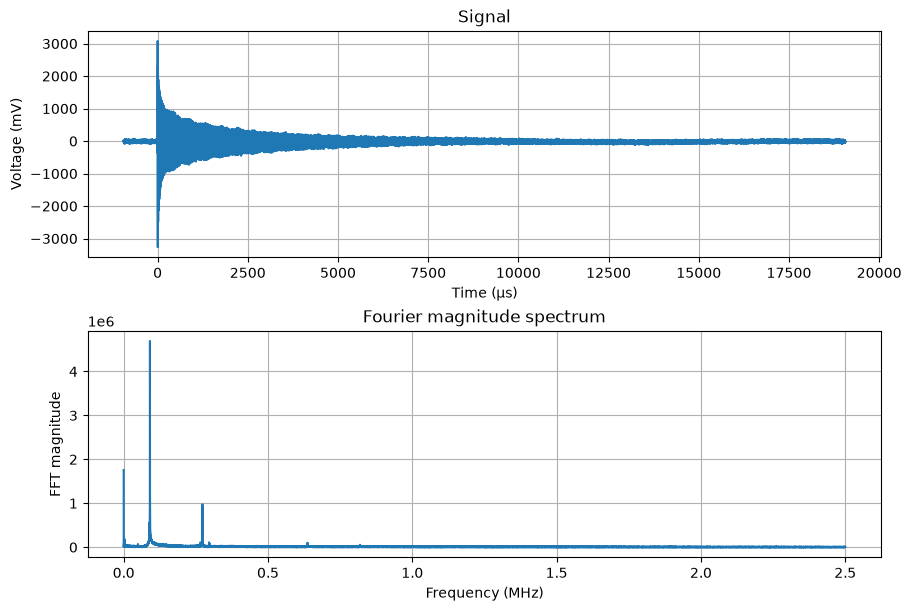

In [ ]:
class DataProcessor:
    def __init__(self, x, y):
        self.x = np.asarray(x, dtype=float)
        self.y = np.asarray(y, dtype=float)

    @classmethod
    def load_data(cls, file_path):
        data = pd.read_csv(file_path, header=None)

        x = pd.to_numeric(data.iloc[:, 3], errors="raise").to_numpy(dtype=float) * 1e6
        y = pd.to_numeric(data.iloc[:, 4], errors="raise").to_numpy(dtype=float) * 1e3

        return cls(x, y)

    def dft(self):
        return np.fft.fft(self.y)

    def plot_data(self):

        sample_interval = self.x[1] - self.x[0]
        frequencies = np.fft.rfftfreq(self.y.size, d=sample_interval)
        magnitude = np.abs(self.dft()[:frequencies.size])

        fig, (ax_time, ax_fft) = plt.subplots(
            2, 1, figsize=(9, 6), layout="constrained"
        )

        ax_time.plot(self.x, self.y)
        ax_time.set(
            title="Signal",
            xlabel="Time (µs)",
            ylabel="Voltage (mV)",
        )
        ax_time.grid(True)

        ax_fft.plot(frequencies, magnitude)
        ax_fft.set(
            title="Fourier magnitude spectrum",
            xlabel="Frequency (MHz)",
            ylabel="FFT magnitude",
        )
        ax_fft.grid(True)

        plt.show()


if __name__ == "__main__":
    FILE_PATH = "../data/k_20ms_avg128_26.5degC.csv"

    processor = DataProcessor.load_data(FILE_PATH)
    processor.plot_data()


    
